# 3. DSP module: `RadarCpiData` + `AntennaModel` → `SensorData`

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from osi_hfss import modules
from osi_hfss.analysis import detection_table, expected_positions
from osi_hfss.data import load
from osi_hfss.messages import over_osi, preview
from osi_hfss.plots import format_spectrum_axes, plot_detections, plot_range_doppler, plot_spectrum

# The inputs: OSI messages of the antenna and the signal generator modules
sensor_view = load("front.sensorview.bin")
antenna = over_osi(load("front.antennamodel.bin"))
cpi = over_osi(load("front.radarcpidata.bin"))
expected = expected_positions(sensor_view)  # direct reflections, for comparison only

  AntennaModel        14698.4 kB
  RadarCpiData         1573.9 kB


## The input, OSI `RadarCpiData`

`RadarCpiData` holds one `RadarCpiFrame` per CPI of the time step.

In [2]:
from osi_hfss import decode

(frame,) = cpi.cpi_frame
print(f"{len(cpi.cpi_frame)} frame: {decode.enum_name(frame.channel[0], 'kind')} channels, "
      f"{decode.enum_name(frame.fast_axis, 'domain')} x {decode.enum_name(frame.slow_axis, 'domain')}, "
      f"data {decode.cpi_cube(frame).shape}, centre frequency {frame.center_frequency / 1e9:.3f} GHz, "
      f"configuration_id {frame.configuration_id.value}")
print(f"antenna: {len(antenna.element)} elements with their own embedded patterns")

1 frame: VIRTUAL channels, RANGE x SLOW_TIME, data (12, 64, 256), centre frequency 76.755 GHz, configuration_id 1
antenna: 7 elements with their own embedded patterns


## Range-Doppler, CFAR and DOA

The detections of the module, `front.sensordata.bin`. 

The physical / fast-time output of the same generator (raw ADC samples, notebook 2) needs the waveform for the MIMO demultiplexing and the range FFT.

Doing these in the generator or in the DSP gives the same detections.

In [3]:
sensor_data, analysis = modules.radar_dsp_with_analysis(cpi, antenna)  # returns SensorData (+ intermediate results for profiling (not OSI))
detections = sensor_data.feature_data.radar_sensor[0].detection
print(detection_table(sensor_data, expected))
print("\nv_r: radial velocity, positive towards the sensor (OSI RadarDetection convention)")

      object | detected: range [m] az [deg] v_r [m/s] SNR [dB] | expected: range [m] az [deg] v_r [m/s]
           3 |               22.13    33.00     16.95     48.5 |               22.05    32.97     16.78
           2 |               56.91     5.50     -4.75     43.3 |               56.77     5.56     -4.98
           1 |               33.02   -27.00      4.75     42.9 |               33.09   -26.95      4.46

v_r: radial velocity, positive towards the sensor (OSI RadarDetection convention)


### Change the input

The DSP trusts the noise floor the CPI reports (`noise_power`): it sets the SNR and the CFAR threshold.

The same CPI with `noise_power` raised by 30 dB, through the same module.

In [4]:
from osi3.osi_radarcpi_pb2 import RadarCpiData

noisier = RadarCpiData()
noisier.CopyFrom(cpi)
noisier.cpi_frame[0].noise_power *= 1e3
print(detection_table(modules.radar_dsp(noisier, antenna), expected))

      object | detected: range [m] az [deg] v_r [m/s] SNR [dB] | expected: range [m] az [deg] v_r [m/s]
           3 |               22.13    33.00     16.95     18.5 |               22.05    32.97     16.78


## Range-Doppler map

The Doppler FFT over slow time (Hann window) and the non-coherent sum over the 12 virtual channels,
relative to the noise floor reported by the CPI, as the DSP module computed it.

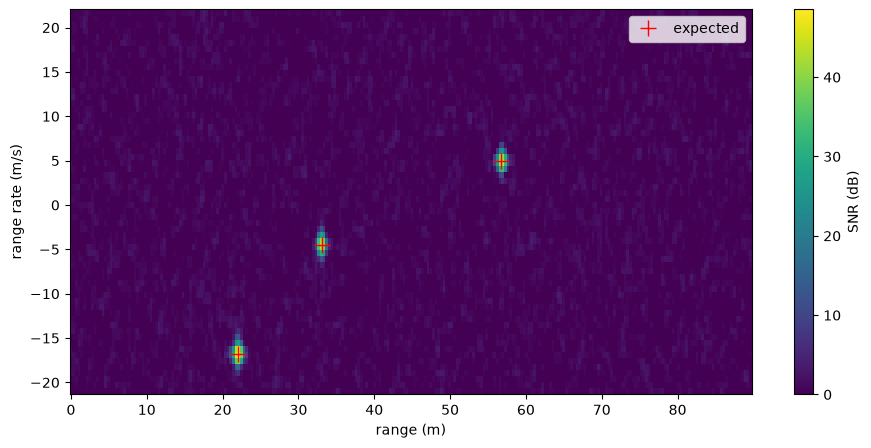

In [5]:
plot_range_doppler(analysis["range"], analysis["range_rate"], analysis["snr"], expected=expected)
plt.show()

## DOA: virtual array vs. one transmitter

Restricting to the channels of Tx0 (a 1×4 SIMO array) shows the resolution gained by the 12-element virtual array.

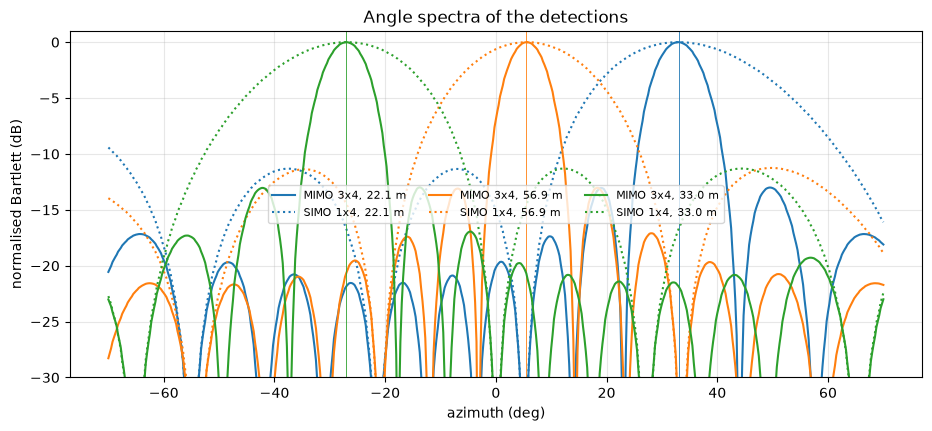

In [6]:
azimuth = analysis["azimuth"]  # the scan grid of the DSP

fig, ax = plt.subplots(figsize=(11, 4.5))
for i, d in enumerate(detections):
    for key, style, label in (("spectrum_antenna", "-", "MIMO 3x4"), ("spectrum_antenna_simo", ":", "SIMO 1x4")):
        plot_spectrum(ax, azimuth, analysis[key][i], style, color=f"C{i}", label=f"{label}, {d.position.distance:.1f} m")
    ax.axvline(np.degrees(d.position.azimuth), color=f"C{i}", lw=0.6)
format_spectrum_axes(ax, "Angle spectra of the detections")
plt.show()

## DOA: antenna model vs. ideal phase centres

The front radar's array has embedded element patterns (mutual coupling).

range [m]   azimuth [deg]: antenna model phase centres expected
    22.13                         33.00         36.75    32.97
    56.91                          5.50          6.25     5.56
    33.02                        -27.00        -30.00   -26.95


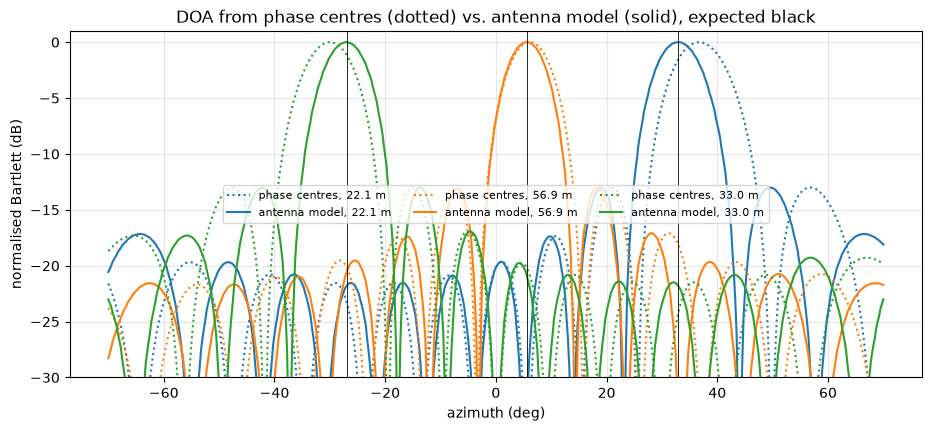

In [7]:
spectra = {"phase centres": analysis["spectrum_phase_centre"], "antenna model": analysis["spectrum_antenna"]}
print(f"{'range [m]':>9}   azimuth [deg]: {'antenna model':>13} {'phase centres':>13} {'expected':>8}")
for i, d in enumerate(detections):
    peak = {label: np.degrees(azimuth[np.argmax(p[i])]) for label, p in spectra.items()}
    e = min(expected, key=lambda e: abs(e.distance - d.position.distance))
    print(f"{d.position.distance:9.2f} {peak['antenna model']:29.2f} {peak['phase centres']:13.2f} {np.degrees(e.azimuth):8.2f}")

fig, ax = plt.subplots(figsize=(11, 4.5))
for i, d in enumerate(detections):
    for (label, p), style in zip(spectra.items(), (":", "-")):
        plot_spectrum(ax, azimuth, p[i], style, color=f"C{i}", label=f"{label}, {d.position.distance:.1f} m")
for e in expected:
    ax.axvline(np.degrees(e.azimuth), color="k", lw=0.6)
format_spectrum_axes(ax, "DOA from phase centres (dotted) vs. antenna model (solid), expected black")
plt.show()

## The output, OSI `SensorData`

One `RadarDetectionData` per CPI frame.

In [8]:
print(preview(sensor_data, max_repeated=1))

version {
  version_major: 3
  version_minor: 8
  version_patch: 0
}
timestamp {
  seconds: 0
  nanos: 2880000
}
sensor_id {
  value: 100
}
mounting_position {
  position {
    x: 3.5
    y: 0
    z: 0.5
  }
  orientation {
    yaw: 0
  }
}
feature_data {
  radar_sensor {
    header {
      measurement_time {
        seconds: 0
        nanos: 0
      }
      cycle_counter: 0
      mounting_position {
        position {
          x: 3.5
          y: 0
          z: 0.5
        }
        orientation {
          yaw: 0
        }
      }
      data_qualifier: DATA_QUALIFIER_AVAILABLE
      number_of_valid_detections: 3
      sensor_id {
        value: 100
      }
    }
    detection {
      existence_probability: 1
      position {
        distance: 22.1331
        azimuth: 0.575959
        elevation: 0
      }
      radial_velocity: 16.9524
      snr: 48.5284
    }
    detection: ... 2 more
  }
}


## Data encoding of the CPI

In [9]:
int16 = modules.fmcw_signal_generator(sensor_view, antenna, load("front.signal_generator.json"), encoding="int16").cpi_frame[0]  # same CPI, int16
reference = decode.cpi_cube(frame)
for f in (frame, int16):
    error = np.mean(np.abs(decode.cpi_cube(f) - reference) ** 2) / f.noise_power
    print(f"{decode.enum_name(f, 'data_encoding'):8s} CPI frame {f.ByteSize() / 1e6:5.2f} MB, encoding error "
          + (f"{10 * np.log10(error):6.1f} dB rel. noise floor" if error > 0 else "(reference)"))

FLOAT32  CPI frame  1.57 MB, encoding error (reference)
INT16    CPI frame  0.79 MB, encoding error  -65.0 dB rel. noise floor


## Detections and their expected positions

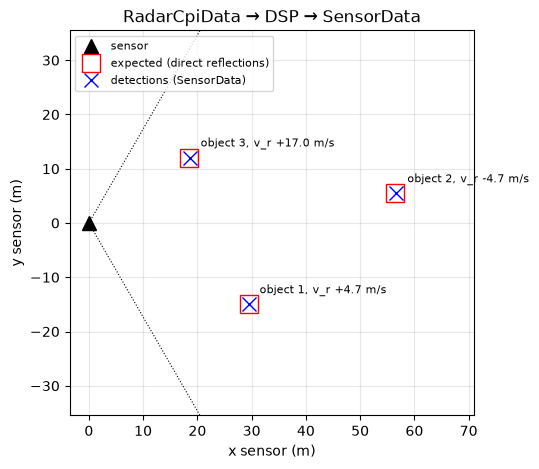

In [10]:
plot_detections(sensor_data, expected, sensor_view.radar_sensor_view[0].view_configuration.field_of_view_horizontal, "RadarCpiData → DSP → SensorData")
plt.show()